##Task 1 : Data Acquisition and Exploration

In [ ]:
!pip install -q opencv-python-headless scikit-learn seaborn tqdm

In [ ]:
# data loading
import os
import requests
import zipfile
import shutil
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from tqdm import tqdm

base_url = "https://fenix.ur.edu.pl/~mkepski/ds/uf.html"

data_dir = "/content/URFD"
raw_dir = os.path.join(data_dir, "raw")
os.makedirs(raw_dir, exist_ok=True)

# get all camera 0 RGB download links
page = requests.get(base_url)
soup = BeautifulSoup(page.text, "html.parser")

download_links = []

for link in soup.find_all("a", href=True):
    href = link["href"]

    if href.endswith(".zip") and "-cam0-rgb" in href:
        download_links.append(urljoin(base_url, href))

print("Total files found:", len(download_links))

# download and extract each file
for url in tqdm(download_links):

    filename = url.split("/")[-1]
    zip_path = os.path.join(raw_dir, filename)

    if not os.path.exists(zip_path):
        response = requests.get(url, stream=True)
        response.raise_for_status()

        with open(zip_path, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024*1024):
                if chunk:
                    f.write(chunk)

    extract_path = os.path.join(raw_dir, filename.replace(".zip", ""))

    if not os.path.exists(extract_path):
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(extract_path)

    os.remove(zip_path)

print("Dataset downloaded and extracted!")
print("Total sequences:", len(download_links))

Total files found: 70


100%|██████████| 70/70 [05:19<00:00,  4.56s/it]

Dataset downloaded and extracted!
Total sequences: 70


In [ ]:
# check dataset files
for folder in sorted(os.listdir(raw_dir))[:10]:
    path = os.path.join(raw_dir, folder)

    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)), "files")

adl-01-cam0-rgb : 1 files
adl-02-cam0-rgb : 1 files
adl-03-cam0-rgb : 1 files
adl-04-cam0-rgb : 1 files
adl-05-cam0-rgb : 1 files
adl-06-cam0-rgb : 1 files
adl-07-cam0-rgb : 1 files
adl-08-cam0-rgb : 1 files
adl-09-cam0-rgb : 1 files
adl-10-cam0-rgb : 1 files


adl-01-cam0-rgb
adl-02-cam0-rgb
adl-03-cam0-rgb
adl-04-cam0-rgb
adl-05-cam0-rgb
adl-06-cam0-rgb
adl-07-cam0-rgb
adl-08-cam0-rgb
adl-09-cam0-rgb
adl-10-cam0-rgb
adl-11-cam0-rgb
adl-12-cam0-rgb
adl-13-cam0-rgb
adl-14-cam0-rgb
adl-15-cam0-rgb
adl-16-cam0-rgb
adl-17-cam0-rgb
adl-18-cam0-rgb
adl-19-cam0-rgb
adl-20-cam0-rgb
adl-21-cam0-rgb
adl-22-cam0-rgb
adl-23-cam0-rgb
adl-24-cam0-rgb
adl-25-cam0-rgb
adl-26-cam0-rgb
adl-27-cam0-rgb
adl-28-cam0-rgb
adl-29-cam0-rgb
adl-30-cam0-rgb
adl-31-cam0-rgb
adl-32-cam0-rgb
adl-33-cam0-rgb
adl-34-cam0-rgb
adl-35-cam0-rgb
adl-36-cam0-rgb
adl-37-cam0-rgb
adl-38-cam0-rgb
adl-39-cam0-rgb
adl-40-cam0-rgb
fall-01-cam0-rgb
fall-02-cam0-rgb
fall-03-cam0-rgb
fall-04-cam0-rgb
fall-05-cam0-rgb
fall-06-cam0-rgb
fall-07-cam0-rgb
fall-08-cam0-rgb
fall-09-cam0-rgb
fall-10-cam0-rgb
fall-11-cam0-rgb
fall-12-cam0-rgb
fall-13-cam0-rgb
fall-14-cam0-rgb
fall-15-cam0-rgb
fall-16-cam0-rgb
fall-17-cam0-rgb
fall-18-cam0-rgb
fall-19-cam0-rgb
fall-20-cam0-rgb
fall-21-cam0-rgb
fal

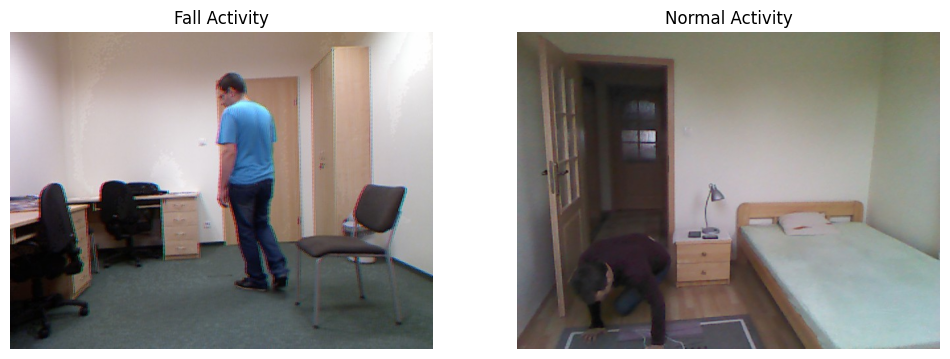

In [ ]:
# check extracted folder names
for folder in sorted(os.listdir(raw_dir)):
    print(folder)

# view sample fall and normal activity frames
import cv2
import matplotlib.pyplot as plt
import glob
import os

fall_folder = None
adl_folder = None

for folder in os.listdir(raw_dir):

    path = os.path.join(raw_dir, folder)

    if not os.path.isdir(path):
        continue

    if folder.lower().startswith("fall-"):
        fall_folder = path

    elif folder.lower().startswith("adl-"):
        adl_folder = path

print("Fall folder:", fall_folder)
print("ADL folder:", adl_folder)

# find image files
fall_frames = sorted(glob.glob(fall_folder + "/**/*.*", recursive=True)) if fall_folder else []
adl_frames = sorted(glob.glob(adl_folder + "/**/*.*", recursive=True)) if adl_folder else []

# keep only image files
extensions = (".png", ".jpg", ".jpeg", ".bmp")

fall_frames = [f for f in fall_frames if f.lower().endswith(extensions)]
adl_frames = [f for f in adl_frames if f.lower().endswith(extensions)]

print("Fall frames:", len(fall_frames))
print("ADL frames:", len(adl_frames))

# display sample images
plt.figure(figsize=(12,5))

for i, frames in enumerate([fall_frames, adl_frames]):

    if len(frames) == 0:
        print("No frames found for", "Fall" if i == 0 else "Normal")
        continue

    frame = cv2.imread(frames[len(frames)//2])
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.subplot(1,2,i+1)
    plt.imshow(frame)
    plt.title("Fall Activity" if i == 0 else "Normal Activity")
    plt.axis("off")

plt.show()

##Task 2 : Data Preprocessing

In [ ]:
# preprocessing setup
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import glob

IMG_SIZE = 112
NUM_FRAMES = 16

# extract frames from all videos
videos = []
labels = []
video_names = []
corrupted = []

for folder in sorted(os.listdir(raw_dir)):

    folder_path = os.path.join(raw_dir, folder)

    if not os.path.isdir(folder_path):
        continue

    if folder.startswith("fall-"):
        label = 1
    elif folder.startswith("adl-"):
        label = 0
    else:
        continue

    # find images inside nested folders
    frames = []

    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith((".png", ".jpg", ".jpeg")):
                frames.append(os.path.join(root, file))

    frames = sorted(frames)

    if len(frames) < 2:
        corrupted.append(folder)
        continue

    # select 16 equally spaced frames
    indices = np.linspace(
        0, len(frames)-1, NUM_FRAMES
    ).astype(int)

    clip = []

    for idx in indices:

        frame = cv2.imread(frames[idx])

        if frame is None:
            clip = []
            break

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (IMG_SIZE, IMG_SIZE))

        clip.append(frame)

    if len(clip) == NUM_FRAMES:

        videos.append(np.array(clip, dtype=np.uint8))
        labels.append(label)
        video_names.append(folder)

    else:
        corrupted.append(folder)

X = np.array(videos, dtype=np.uint8)
y = np.array(labels)

print("Video tensor shape:", X.shape)
print("Total videos:", len(X))
print("Fall videos:", np.sum(y == 1))
print("Normal videos:", np.sum(y == 0))
print("Corrupted videos:", len(corrupted))

Video tensor shape: (70, 16, 112, 112, 3)
Total videos: 70
Fall videos: 30
Normal videos: 40
Corrupted videos: 0


In [ ]:
# normalize pixel values
X = X.astype("float32") / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


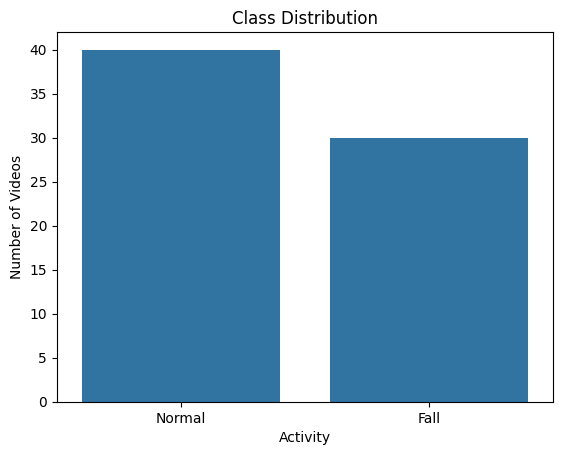

In [ ]:
# check class imbalance
import seaborn as sns

sns.countplot(x=y)

plt.xticks([0, 1], ["Normal", "Fall"])
plt.title("Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Videos")
plt.show()

In [ ]:
# split the dataset
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp, name_train, name_temp = train_test_split(
    X, y, video_names,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test, name_val, name_test = train_test_split(
    X_temp, y_temp, name_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (49, 16, 112, 112, 3)
Validation data: (10, 16, 112, 112, 3)
Testing data: (11, 16, 112, 112, 3)


In [ ]:
# data augmentation
def augment_video(video, label):

    # random horizontal flip
    video = tf.cond(
        tf.random.uniform(()) > 0.5,
        lambda: tf.reverse(video, axis=[2]),
        lambda: video
    )

    # random crop
    offset_h = tf.random.uniform([], 0, 9, dtype=tf.int32)
    offset_w = tf.random.uniform([], 0, 9, dtype=tf.int32)

    video = video[:, offset_h:offset_h+104, offset_w:offset_w+104, :]

    video = tf.image.resize(video, (IMG_SIZE, IMG_SIZE))

    # temporal frame shifting
    shift = tf.random.uniform([], -2, 3, dtype=tf.int32)
    video = tf.roll(video, shift=shift, axis=0)

    return video, label

In [ ]:
# prepare training and testing datasets
BATCH_SIZE = 4

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_ds = (
    train_ds
    .shuffle(len(X_train))
    .map(augment_video, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(BATCH_SIZE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
).batch(BATCH_SIZE)

print("Training, validation and testing datasets are ready!")

Training, validation and testing datasets are ready!


In [ ]:
# calculate class weights
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    i: weight for i, weight in enumerate(weights)
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(0.875), 1: np.float64(1.1666666666666667)}


In [ ]:
# verify preprocessed data
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining labels:", np.unique(y_train, return_counts=True))
print("Validation labels:", np.unique(y_val, return_counts=True))
print("Testing labels:", np.unique(y_test, return_counts=True))

print("\nVideo dimensions:", X_train.shape[1:])
print("Pixel range:", X_train.min(), "to", X_train.max())

Training: (49, 16, 112, 112, 3)
Validation: (10, 16, 112, 112, 3)
Testing: (11, 16, 112, 112, 3)

Training labels: (array([0, 1]), array([28, 21]))
Validation labels: (array([0, 1]), array([6, 4]))
Testing labels: (array([0, 1]), array([6, 5]))

Video dimensions: (16, 112, 112, 3)
Pixel range: 0.0 to 1.0


##Task 3 : Model Training and Basic Evaluation

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [ ]:
# build 3D CNN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv3D, MaxPooling3D, Dense,
    Dropout, BatchNormalization,
    GlobalAveragePooling3D
)

model = Sequential([

    tf.keras.Input(shape=(16, 112, 112, 3)),

    Conv3D(16, (3,3,3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling3D((1,2,2)),

    Conv3D(32, (3,3,3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling3D((2,2,2)),

    Conv3D(64, (3,3,3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling3D((2,2,2)),

    GlobalAveragePooling3D(),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 112, 112,   │            64 │
│ (BatchNormalization)            │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 56, 56, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 28, 28, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,201 (293.75 KB)

 Trainable params: 74,977 (292.88 KB)

 Non-trainable params: 224 (896.00 B)

In [ ]:
# compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
# train the model
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 78s 5s/step - accuracy: 0.5102 - auc: 0.5680 - loss: 0.7286 - val_accuracy: 0.4000 - val_auc: 0.7500 - val_loss: 0.6968
Epoch 2/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 64s 5s/step - accuracy: 0.6327 - auc: 0.7083 - loss: 0.6118 - val_accuracy: 0.4000 - val_auc: 0.8750 - val_loss: 0.7044
Epoch 3/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 50s 4s/step - accuracy: 0.6939 - auc: 0.7857 - loss: 0.5718 - val_accuracy: 0.4000 - val_auc: 0.7083 - val_loss: 0.7107
Epoch 4/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 51s 4s/step - accuracy: 0.7143 - auc: 0.7951 - loss: 0.5285 - val_accuracy: 0.4000 - val_auc: 0.6667 - val_loss: 0.7163
Epoch 5/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 47s 4s/step - accuracy: 0.7143 - auc: 0.8878 - loss: 0.4750 - val_accuracy: 0.4000 - val_auc: 0.6667 - val_loss: 0.7191
Epoch 6/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 49s 4s/step - accuracy: 0.7143 - auc: 0.8359 - loss: 0.4979 - val_accuracy: 0.4000 - val_auc: 0.6667 - val_loss: 0.7218


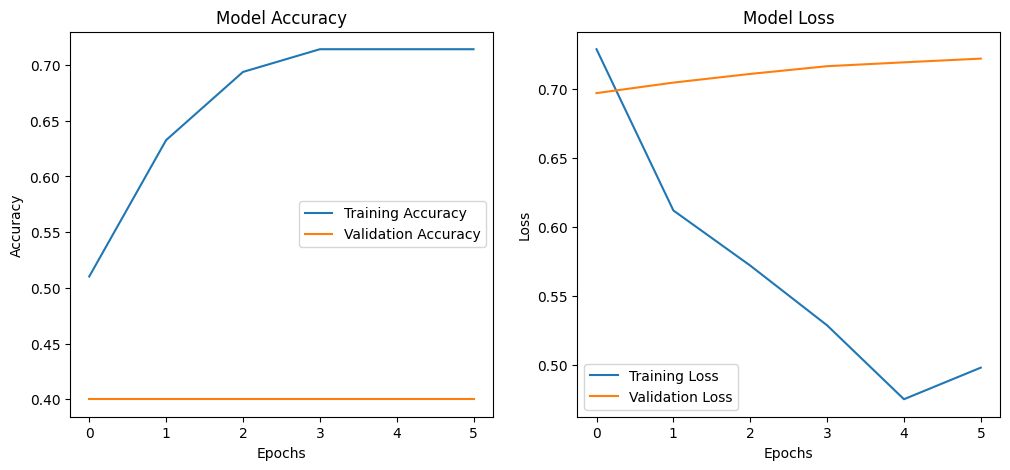

In [ ]:
# plot training performance
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
# evaluate model on test data
test_loss, test_accuracy, test_auc = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test AUROC:", round(test_auc, 4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 660ms/step - accuracy: 0.4545 - auc: 0.8167 - loss: 0.6920
Test Loss: 0.692
Test Accuracy: 0.4545
Test AUROC: 0.8167


In [ ]:
# generate predictions
y_prob = model.predict(test_ds).flatten()

y_pred = (y_prob >= 0.5).astype(int)

print("Actual labels:", y_test)
print("Predicted labels:", y_pred)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 743ms/step
Actual labels: [0 0 0 1 0 1 1 0 0 1 1]
Predicted labels: [1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
# calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc_score = roc_auc_score(y_test, y_prob)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("AUROC    :", round(auc_score, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal Activity", "Fall Activity"],
    zero_division=0
))

Accuracy : 0.4545
Precision: 0.4545
Recall   : 1.0
F1 Score : 0.625
AUROC    : 0.9

Classification Report:

                 precision    recall  f1-score   support

Normal Activity       0.00      0.00      0.00         6
  Fall Activity       0.45      1.00      0.62         5

       accuracy                           0.45        11
      macro avg       0.23      0.50      0.31        11
   weighted avg       0.21      0.45      0.28        11



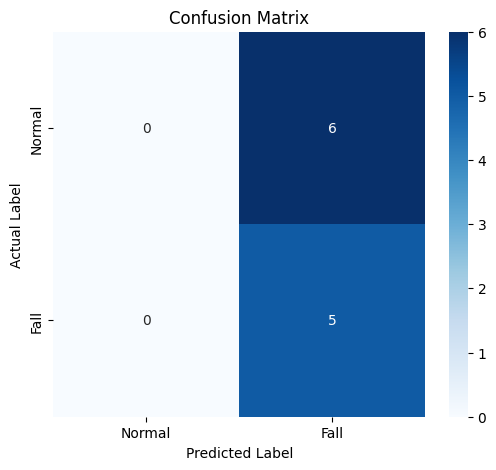

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fall"],
    yticklabels=["Normal", "Fall"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

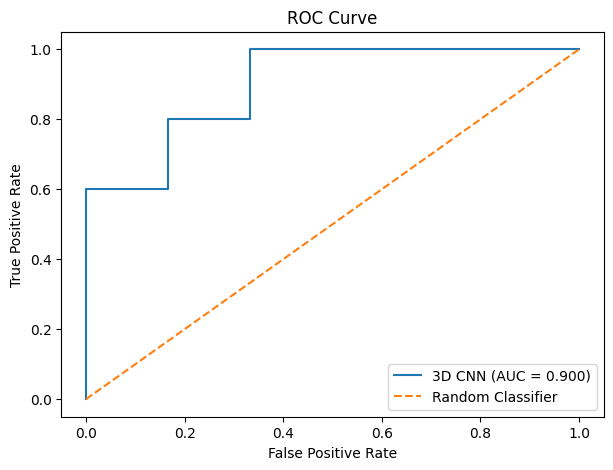

In [ ]:
# ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"3D CNN (AUC = {auc_score:.3f})"
)

plt.plot([0,1], [0,1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

In [ ]:
# identify wrongly classified videos
for i in range(len(y_test)):

    if y_test[i] != y_pred[i]:

        actual = "Fall" if y_test[i] == 1 else "Normal"
        predicted = "Fall" if y_pred[i] == 1 else "Normal"

        print("Video:", name_test[i])
        print("Actual:", actual)
        print("Predicted:", predicted)
        print("-----------------------")

Video: adl-11-cam0-rgb
Actual: Normal
Predicted: Fall
-----------------------
Video: adl-29-cam0-rgb
Actual: Normal
Predicted: Fall
-----------------------
Video: adl-15-cam0-rgb
Actual: Normal
Predicted: Fall
-----------------------
Video: adl-33-cam0-rgb
Actual: Normal
Predicted: Fall
-----------------------
Video: adl-23-cam0-rgb
Actual: Normal
Predicted: Fall
-----------------------
Video: adl-36-cam0-rgb
Actual: Normal
Predicted: Fall
-----------------------


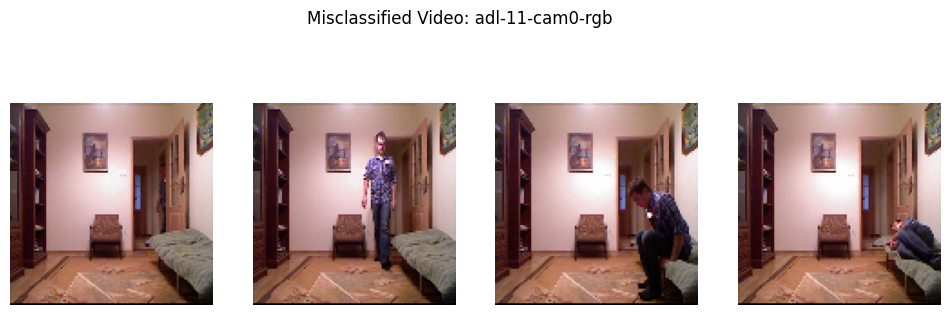

In [ ]:
# visualize a misclassified video
wrong_indices = np.where(y_test != y_pred)[0]

if len(wrong_indices) > 0:

    idx = wrong_indices[0]

    plt.figure(figsize=(12,4))

    for i in range(4):

        frame = X_test[idx][i*4]

        plt.subplot(1,4,i+1)
        plt.imshow(frame)
        plt.axis("off")

    plt.suptitle("Misclassified Video: " + name_test[idx])
    plt.show()

else:
    print("No misclassified videos found!")

In [ ]:
# analyze prediction errors
cm = confusion_matrix(y_test, y_pred)

print("False Positives:", cm[0][1])
print("False Negatives:", cm[1][0])

print("\nPossible reasons for misclassification:")
print("1. Camera view differences.")
print("2. Body occlusion or blocked visibility.")
print("3. Motion blur during sudden movements.")
print("4. Normal activities resembling falling movements.")

False Positives: 6
False Negatives: 0

Possible reasons for misclassification:
1. Camera view differences.
2. Body occlusion or blocked visibility.
3. Motion blur during sudden movements.
4. Normal activities resembling falling movements.


In [ ]:
# save trained model
model.save("/content/fall_detection_3dcnn.keras")

print("Model saved successfully!")

Model saved successfully!
